<a href="https://colab.research.google.com/github/moyaandres1099/Tarea-02/blob/main/Tarea_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vinculación del patrimonio cultural del Territorio Huetar de Zapatón en el Plan de Manejo del Parque Nacional La Cangreja

## Introducción
### El presente trabajo tiene como tema central el análisis espacial de la relación territorial entre el Territorio Indígena Huetar de Zapatón y el Parque Nacional La Cangreja, ubicados en el cantón de Puriscal, provincia de San José, Costa Rica. Esta área de estudio resulta de interés geográfico debido a la proximidad entre ambos espacios, así como a su importancia sociocultural y ambiental. El Territorio Indígena de Zapatón se localiza en el distrito de Chires, mientras que el Parque Nacional La Cangreja comprende sectores de los distritos de Chires y Mercedes Sur. Esta relación territorial permite estudiar su distribución espacial, sus características geográficas y la forma en que se relacionan sus delimitaciones.

## Preguntas a responder

### ¿En cuáles distritos del cantón de Puriscal se localizan el Territorio Indígena Huetar de Zapatón y el Parque Nacional La Cangreja?
###¿Cuáles ríos y quebradas atraviesan o se encuentran próximos al Territorio Indígena Huetar de Zapatón y al Parque Nacional La Cangreja?
###¿En qué zona existe el traslape territorial entre el Territorio Indígena Huetar de Zapatón y el Parque Nacional La Cangreja?


### Para responder estas preguntas se utilizarán datos geográficos provenientes de fuentes institucionales, principalmente del Sistema Nacional de Información Territorial (SNIT), el Instituto Geográfico Nacional (IGN) y el Sistema Nacional de Áreas de Conservación (SINAC).
### Estas son las fuentes:
###SNIT / IGN	Límites político-administrativos y cartografía oficial.
###SINAC	Información del Parque Nacional La Cangreja.


## Descripción de las capas
### 1. Límites político-administrativos
### •	Geometría: polígono.
### •	SRC: por verificar.
### •	Variables: provincia, cantón, distrito y códigos territoriales.
### Fuente: IGN / SNIT.
### 2. Territorio Indígena Huetar de Zapatón
### •	Geometría: polígono.
### •	SRC: por verificar.
### •	Variables: nombre del territorio, código identificador y área, según los atributos disponibles.
###Fuente: cartografía institucional.
### 3. Parque Nacional La Cangreja
### •	Geometría: polígono.
### •	SRC: por verificar.
### •	Variables: nombre del área silvestre protegida, categoría de manejo, código y superficie, según disponibilidad.
### Fuente: SINAC / SNIT.



## Busqueda de información

In [3]:
import geopandas as gpd

DATOS_NE = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/natural-earth"

paises = gpd.read_file(DATOS_NE + "/paises.gpkg")
centroamerica = gpd.read_file(DATOS_NE + "/centroamerica.gpkg")

In [4]:
import requests

url = "https://api.github.com/repos/gf0657-programacionsig/2026-ii/contents/datos"

respuesta = requests.get(url)

if respuesta.status_code == 200:
    for archivo in respuesta.json():
        print(archivo["name"])
else:
    print("Error:", respuesta.status_code)

banco-mundial
ign
inec
ministerio-salud
natural-earth
sentinel
worldclim


In [5]:
import requests

url = "https://api.github.com/repos/gf0657-programacionsig/2026-ii/git/trees/main?recursive=1"

respuesta = requests.get(url)

if respuesta.status_code == 200:
    archivos = respuesta.json()["tree"]

    formatos = (".gpkg", ".geojson", ".shp", ".zip", ".parquet")

    for archivo in archivos:
        if archivo["path"].lower().endswith(formatos):
            print(archivo["path"])
else:
    print("Error:", respuesta.status_code)

datos/ign/aerodromos.gpkg
datos/ign/cantones.gpkg
datos/ign/provincias.gpkg
datos/natural-earth/aeropuertos.gpkg
datos/natural-earth/centroamerica.gpkg
datos/natural-earth/lagos.gpkg
datos/natural-earth/paises.gpkg
datos/natural-earth/rios.gpkg


In [6]:
import requests

# Consultar los archivos del repositorio
url = "https://api.github.com/repos/gf0657-programacionsig/2026-ii/git/trees/main?recursive=1"

respuesta = requests.get(url)

if respuesta.status_code == 200:

    archivos = respuesta.json()["tree"]

    # Formatos de archivos geográficos
    formatos = (".gpkg", ".geojson", ".shp", ".zip", ".parquet")

    print("Archivos geográficos encontrados:\n")

    for archivo in archivos:
        if archivo["path"].lower().endswith(formatos):
            print(archivo["path"])

else:
    print("Error al consultar el repositorio:", respuesta.status_code)

Archivos geográficos encontrados:

datos/ign/aerodromos.gpkg
datos/ign/cantones.gpkg
datos/ign/provincias.gpkg
datos/natural-earth/aeropuertos.gpkg
datos/natural-earth/centroamerica.gpkg
datos/natural-earth/lagos.gpkg
datos/natural-earth/paises.gpkg
datos/natural-earth/rios.gpkg


In [7]:
import geopandas as gpd

DATOS_IGN = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/ign"

cantones = gpd.read_file(DATOS_IGN + "/cantones.gpkg")

print(cantones.head())
print(cantones.columns)
print(cantones.crs)

   codigo_provincia provincia  codigo_canton        canton  \
0                 1  San José            101      San José   
1                 1  San José            102        Escazú   
2                 1  San José            103  Desamparados   
3                 1  San José            104      Puriscal   
4                 1  San José            105       Tarrazú   

                                            geometry  
0  MULTIPOLYGON (((481030.294 1102633.121, 481510...  
1  MULTIPOLYGON (((479844.884 1102669.54, 479982....  
2  MULTIPOLYGON (((494091.189 1094936.765, 494448...  
3  MULTIPOLYGON (((455732.107 1095962.406, 456519...  
4  MULTIPOLYGON (((501118.557 1074475.546, 502323...  
Index(['codigo_provincia', 'provincia', 'codigo_canton', 'canton', 'geometry'], dtype='object')
EPSG:8908


In [12]:
# Capa de distritos
url_distritos = (
    "https://services5.arcgis.com/4u1m1BBDkNDTVWsd/"
    "arcgis/rest/services/Distritos_CR/FeatureServer/0/query"
    "?where=1%3D1&outFields=*&returnGeometry=true"
    "&outSR=4326&f=geojson"
)

distritos = gpd.read_file(url_distritos)


# Capa de territorios indígenas (Filtrada para ZAPATÓN desde el servidor para evitar truncamiento del GeoJSON)
url_territorios = (
    "https://services1.arcgis.com/aWQmxJWy7lM2Qqmo/"
    "arcgis/rest/services/CE_Publicos_CR/FeatureServer/4/query"
    "?where=Nombre%3D%27ZAPAT%C3%93N%27&outFields=*&returnGeometry=true"
    "&outSR=4326&f=geojson"
)

territorios = gpd.read_file(url_territorios)

In [48]:
# Asegurar la definición de las variables principales tras la descarga
distritos_puriscal = distritos[
    distritos["canton"].str.strip().str.upper() == "PURISCAL"
].copy()

# Como 'territorios' ya viene filtrado desde el servidor con Zapatón:
zapaton = territorios.copy()

print("DISTRITOS DE PURISCAL")
print(distritos_puriscal.head())
print(distritos_puriscal.columns)
print(distritos_puriscal.crs)

print("\nTERRITORIO INDÍGENA ZAPATÓN")
print(zapaton.head())
print(zapaton.columns)
print(zapaton.crs)

DISTRITOS DE PURISCAL
    OBJECTID_12  nom_prov    canton  poblacion     nom_distr cod_distr  \
56           57  San José  PURISCAL          0        CHIRES         9   
74           75  San José  PURISCAL          0   CANDELARITA         6   
78           79  San José  PURISCAL          0  MERCEDES SUR         2   
79           80  San José  PURISCAL          0    SAN RAFAEL         5   
97           98  San José  PURISCAL          0     BARBACOAS         3   

      area_km2   perime_km  cod_canton   Shape__Area  Shape__Length  \
56  229.658531  106.369479         104  2.296585e+08  106369.478840   
74   24.944120   28.719686         104  2.494412e+07   28719.685937   
78  183.552704   88.575853         104  1.835527e+08   88575.852553   
79   15.499943   24.438752         104  1.549994e+07   24438.751608   
97   18.616210   20.009449         104  1.861621e+07   20009.448754   

                                             geometry  
56  POLYGON ((-84.38961 9.74766, -84.38945 9.74707

In [14]:
print(territorios.columns.tolist())

['FID', 'OBJECTID', 'AreaOfi', 'Pueblo', 'Nombre', 'Poblacion', 'DecrCreac', 'DecrDeli', 'RepreLegal', 'HojaCarto', 'Poblados', 'SHAPE_STAr', 'SHAPE_STLe', 'Field', 'Shape__Area', 'Shape__Length', 'geometry']


In [15]:
# Mostrar todos los campos disponibles
for columna in territorios.columns:
    print(columna)

FID
OBJECTID
AreaOfi
Pueblo
Nombre
Poblacion
DecrCreac
DecrDeli
RepreLegal
HojaCarto
Poblados
SHAPE_STAr
SHAPE_STLe
Field
Shape__Area
Shape__Length
geometry


In [16]:
print(territorios.head(3).to_string())

   FID  OBJECTID  AreaOfi  Pueblo   Nombre  Poblacion  DecrCreac   DecrDeli                                                        RepreLegal HojaCarto Poblados    SHAPE_STAr    SHAPE_STLe  Field   Shape__Area  Shape__Length                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [17]:
for columna in territorios.columns:
    print(f"\n{columna}")
    print(territorios[columna].head(5).tolist())


FID
[1]

OBJECTID
[1]

AreaOfi
[2855]

Pueblo
['HUETAR']

Nombre
['ZAPATÓN']

Poblacion
[800]

DecrCreac
['D 13569-D']

DecrDeli
['D 12812-G']

RepreLegal
['ASOCIACION DE DESARROLLO INTEGRAL DE LA RESERVA INDIGENA ZAPATON']

HojaCarto
[' ']

Poblados
[' ']

SHAPE_STAr
[34980043.1818]

SHAPE_STLe
[29197.241377]

Field
[0]

Shape__Area
[34980043.18057251]

Shape__Length
[29197.241314012197]

geometry
[<POLYGON ((-84.354 9.721, -84.353 9.721, -84.353 9.721, -84.353 9.721, -84.3...>]


In [22]:
# Filtrar el Territorio Indígena Huetar de Zapatón
zapaton = territorios[
    territorios["Nombre"] == "ZAPATÓN"
].copy()

# Mostrar información
print(zapaton[["Nombre", "Pueblo", "Poblacion"]])

    Nombre  Pueblo  Poblacion
0  ZAPATÓN  HUETAR        800


In [23]:
print("Registros encontrados:", len(zapaton))
print("Sistema de coordenadas:", zapaton.crs)

Registros encontrados: 1
Sistema de coordenadas: EPSG:4326


In [20]:
import geopandas as gpd
import requests

# URL del servicio geográfico
url_parque = "https://services.arcgis.com/"

# Consultar servicios disponibles

In [25]:
# Definir las variables necesarias antes de imprimirlas
distritos_puriscal = distritos[
    distritos["canton"].str.strip().str.upper() == "PURISCAL"
].copy()

zapaton = territorios.copy()

print("DISTRITOS DE PURISCAL")
print(distritos_puriscal[["canton", "nom_distr"]])

print("\nTERRITORIO HUETAR DE ZAPATÓN")
print(zapaton[["Nombre", "Pueblo", "Poblacion"]])

print("\nSISTEMAS DE COORDENADAS")
print("Distritos:", distritos_puriscal.crs)
print("Zapatón:", zapaton.crs)

DISTRITOS DE PURISCAL
       canton       nom_distr
56   PURISCAL          CHIRES
74   PURISCAL     CANDELARITA
78   PURISCAL    MERCEDES SUR
79   PURISCAL      SAN RAFAEL
97   PURISCAL       BARBACOAS
99   PURISCAL        SANTIAGO
107  PURISCAL     SAN ANTONIO
119  PURISCAL  DESAMPARADITOS
130  PURISCAL      GRIFO ALTO

TERRITORIO HUETAR DE ZAPATÓN
    Nombre  Pueblo  Poblacion
0  ZAPATÓN  HUETAR        800

SISTEMAS DE COORDENADAS
Distritos: EPSG:4326
Zapatón: EPSG:4326


In [26]:
import geopandas as gpd
import requests

In [27]:
# URL del servicio ArcGIS REST
url_asp = (
    "https://services9.arcgis.com/RrvMEynxDB8hycVO/"
    "ArcGIS/rest/services/ÁSP_Costa_Rica_2021/FeatureServer/0/query"
)

# Parámetros de consulta
params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

# Realizar la consulta
response = requests.get(url_asp, params=params)
response.raise_for_status()

# Convertir la respuesta a GeoDataFrame
datos_asp = response.json()

areas_protegidas = gpd.GeoDataFrame.from_features(
    datos_asp["features"],
    crs="EPSG:4326"
)

In [28]:
# Filtrar el Parque Nacional La Cangreja
cangreja = areas_protegidas[
    areas_protegidas["nombre_asp"].str.contains(
        "La Cangreja",
        case=False,
        na=False
    )
].copy()

# Mostrar información
print(cangreja[["nombre_asp", "cat_manejo", "area_km"]])

     nombre_asp       cat_manejo        area_km
48  La Cangreja  Parque Nacional  257379.317146


## Representación del Parque Nacional La Cangreja

Registros encontrados: 1
Sistema de coordenadas: EPSG:4326
Tipo de geometría: ['Polygon']


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

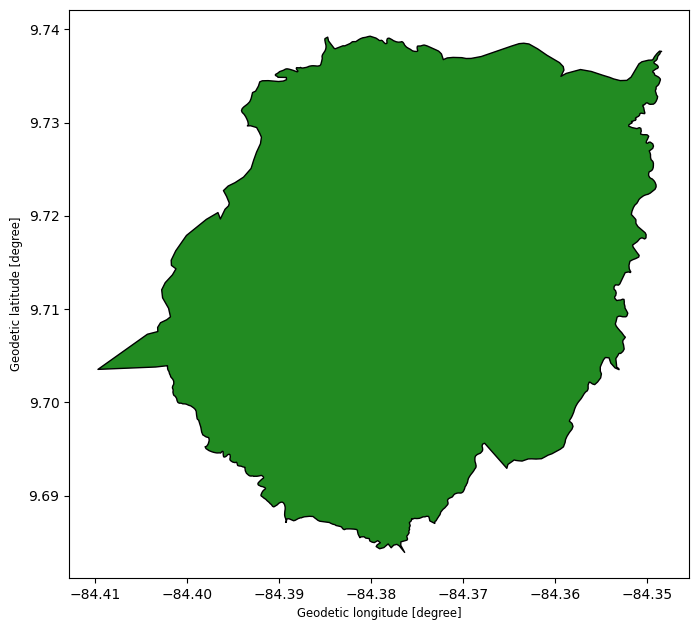

In [30]:
print("Registros encontrados:", len(cangreja))
print("Sistema de coordenadas:", cangreja.crs)
print("Tipo de geometría:", cangreja.geom_type.unique())

# Visualizar el polígono
cangreja.plot(
    figsize=(8, 8),
    edgecolor="black",
    color="forestgreen"
)

In [31]:
print("Distritos de Puriscal:", len(distritos_puriscal))
print("Territorio Huetar de Zapatón:", len(zapaton))
print("Parque Nacional La Cangreja:", len(cangreja))

Distritos de Puriscal: 9
Territorio Huetar de Zapatón: 1
Parque Nacional La Cangreja: 1


In [32]:
# Unificar el sistema de coordenadas
zapaton = zapaton.to_crs(epsg=4326)
cangreja = cangreja.to_crs(epsg=4326)
distritos_puriscal = distritos_puriscal.to_crs(epsg=4326)

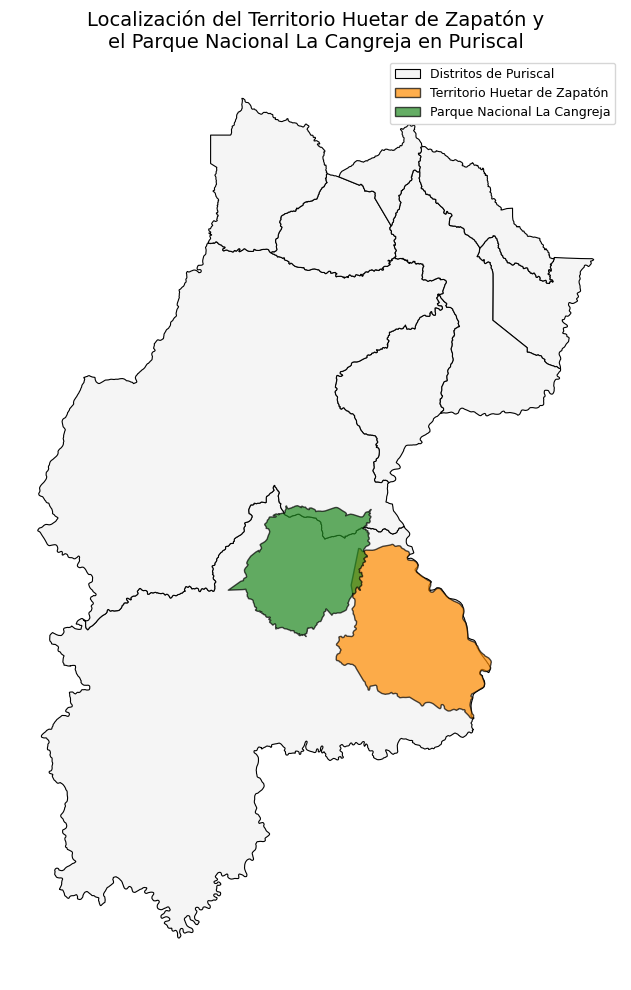

In [33]:
import matplotlib.pyplot as plt

# Crear figura y ejes
fig, ax = plt.subplots(figsize=(12, 10))

# Dibujar los distritos de Puriscal
distritos_puriscal.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8,
    label="Distritos de Puriscal"
)

# Dibujar el Territorio Indígena Huetar de Zapatón
zapaton.plot(
    ax=ax,
    color="darkorange",
    edgecolor="black",
    alpha=0.7,
    label="Territorio Huetar de Zapatón"
)

# Dibujar el Parque Nacional La Cangreja
cangreja.plot(
    ax=ax,
    color="forestgreen",
    edgecolor="black",
    alpha=0.7,
    label="Parque Nacional La Cangreja"
)

# Título y leyenda
ax.set_title(
    "Localización del Territorio Huetar de Zapatón y\n"
    "el Parque Nacional La Cangreja en Puriscal",
    fontsize=14
)

ax.legend(loc="best", fontsize=9)

# Eliminar ejes
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [34]:
# Relacionar el Territorio Huetar de Zapatón con los distritos
resultado_zapaton = gpd.sjoin(
    distritos_puriscal,
    zapaton,
    how="inner",
    predicate="intersects"
)

# Relacionar el Parque Nacional La Cangreja con los distritos
resultado_cangreja = gpd.sjoin(
    distritos_puriscal,
    cangreja,
    how="inner",
    predicate="intersects"
)

# Mostrar los distritos correspondientes
print("Distritos donde se localiza el Territorio Huetar de Zapatón:")
print(resultado_zapaton[["nom_distr"]])

print("\nDistritos donde se localiza el Parque Nacional La Cangreja:")
print(resultado_cangreja[["nom_distr"]])

Distritos donde se localiza el Territorio Huetar de Zapatón:
   nom_distr
56    CHIRES

Distritos donde se localiza el Parque Nacional La Cangreja:
       nom_distr
56        CHIRES
78  MERCEDES SUR


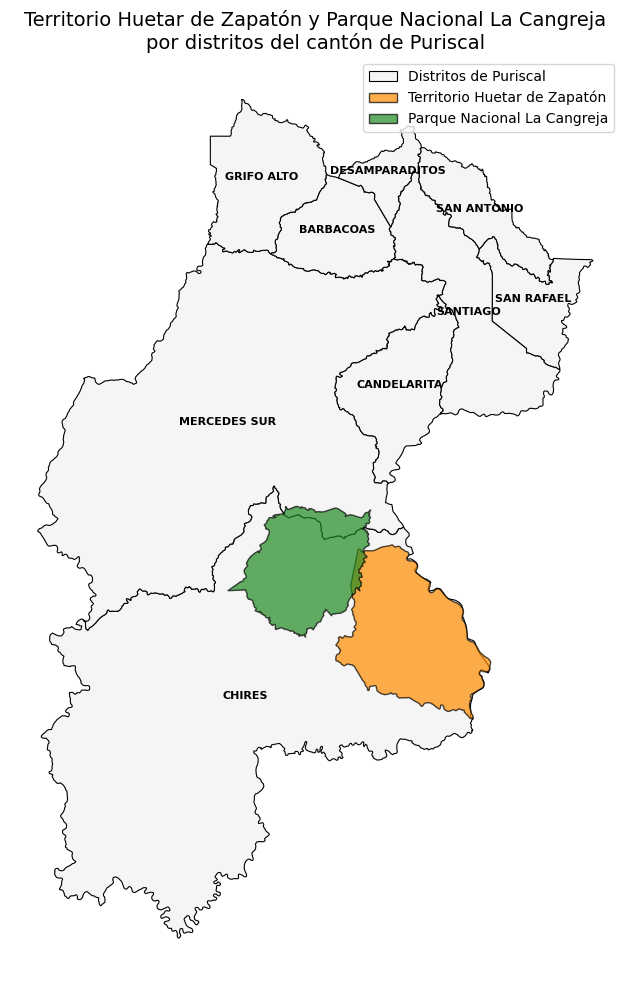

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

# Distritos de Puriscal
distritos_puriscal.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8
)

# Territorio Huetar de Zapatón
zapaton.plot(
    ax=ax,
    color="darkorange",
    edgecolor="black",
    alpha=0.7
)

# Parque Nacional La Cangreja
cangreja.plot(
    ax=ax,
    color="forestgreen",
    edgecolor="black",
    alpha=0.7
)

# Nombres de los distritos
for idx, row in distritos_puriscal.iterrows():
    centroide = row.geometry.centroid

    ax.annotate(
        text=row["nom_distr"],
        xy=(centroide.x, centroide.y),
        ha="center",
        fontsize=8,
        color="black",
        weight="bold"
    )

# Título y leyenda
ax.set_title(
    "Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
    "por distritos del cantón de Puriscal",
    fontsize=14
)

ax.legend(
    ["Distritos de Puriscal",
     "Territorio Huetar de Zapatón",
     "Parque Nacional La Cangreja"],
    loc="best"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

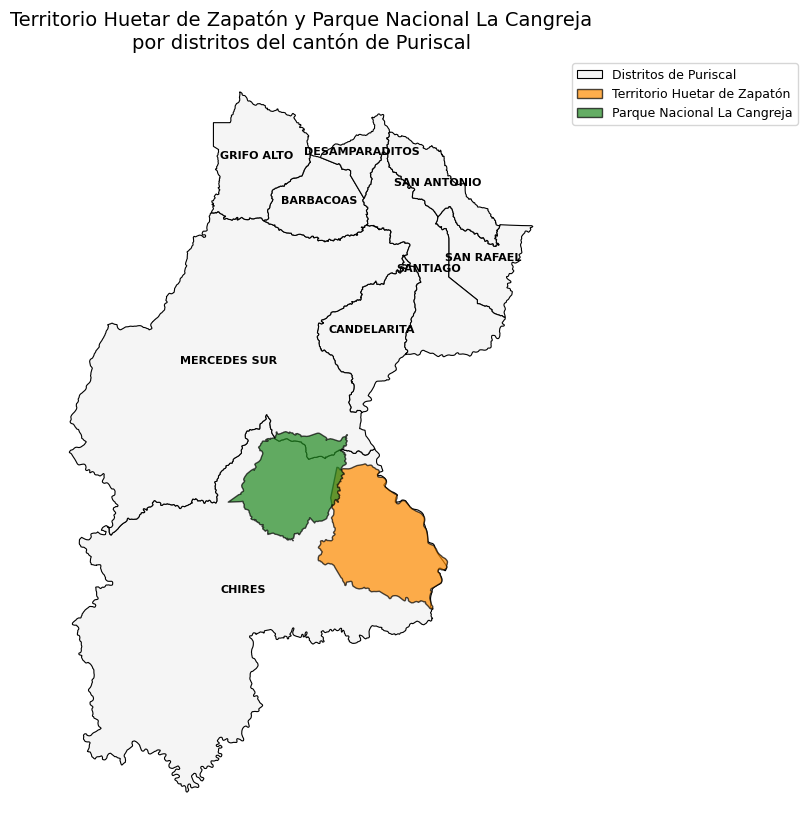

In [36]:
import matplotlib.pyplot as plt

# Crear figura y ejes
fig, ax = plt.subplots(figsize=(12, 10))

# Distritos de Puriscal
distritos_puriscal.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8,
    label="Distritos de Puriscal"
)

# Territorio Huetar de Zapatón
zapaton.plot(
    ax=ax,
    color="darkorange",
    edgecolor="black",
    alpha=0.7,
    label="Territorio Huetar de Zapatón"
)

# Parque Nacional La Cangreja
cangreja.plot(
    ax=ax,
    color="forestgreen",
    edgecolor="black",
    alpha=0.7,
    label="Parque Nacional La Cangreja"
)

# Nombres de los distritos
for idx, row in distritos_puriscal.iterrows():
    centroide = row.geometry.centroid

    ax.annotate(
        text=row["nom_distr"],
        xy=(centroide.x, centroide.y),
        ha="center",
        fontsize=8,
        color="black",
        weight="bold"
    )

# Título
ax.set_title(
    "Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
    "por distritos del cantón de Puriscal",
    fontsize=14
)

# Leyenda fuera del mapa
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

# Reservar espacio para la leyenda
fig.subplots_adjust(right=0.75)

# Eliminar ejes
ax.set_axis_off()

# Mostrar mapa
plt.show()

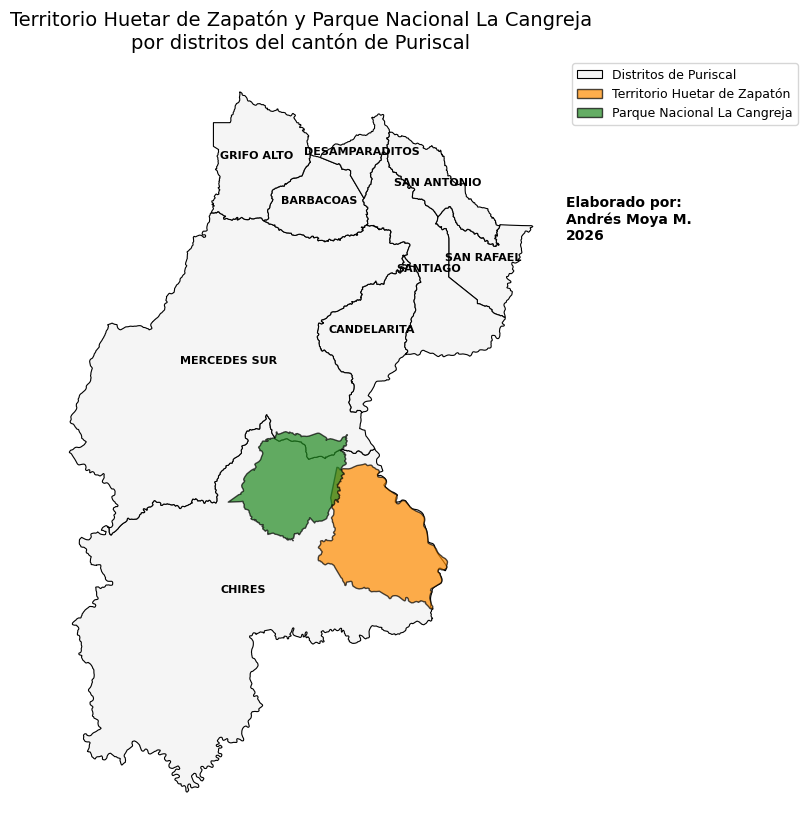

In [37]:
import matplotlib.pyplot as plt

# Crear figura y ejes
fig, ax = plt.subplots(figsize=(12, 10))

# Distritos de Puriscal
distritos_puriscal.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8,
    label="Distritos de Puriscal"
)

# Territorio Huetar de Zapatón
zapaton.plot(
    ax=ax,
    color="darkorange",
    edgecolor="black",
    alpha=0.7,
    label="Territorio Huetar de Zapatón"
)

# Parque Nacional La Cangreja
cangreja.plot(
    ax=ax,
    color="forestgreen",
    edgecolor="black",
    alpha=0.7,
    label="Parque Nacional La Cangreja"
)

# Nombres de los distritos
for idx, row in distritos_puriscal.iterrows():
    centroide = row.geometry.centroid

    ax.annotate(
        text=row["nom_distr"],
        xy=(centroide.x, centroide.y),
        ha="center",
        fontsize=8,
        color="black",
        weight="bold"
    )

# Título del mapa
ax.set_title(
    "Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
    "por distritos del cantón de Puriscal",
    fontsize=14
)

# Leyenda a la derecha
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

# Nombre y año debajo de la leyenda
ax.text(
    1.02, 0.82,
    "Elaborado por:\nAndrés Moya M.\n2026",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="top",
    weight="bold"
)

# Reservar espacio a la derecha
fig.subplots_adjust(right=0.72)

# Eliminar ejes
ax.set_axis_off()

# Mostrar mapa
plt.show()

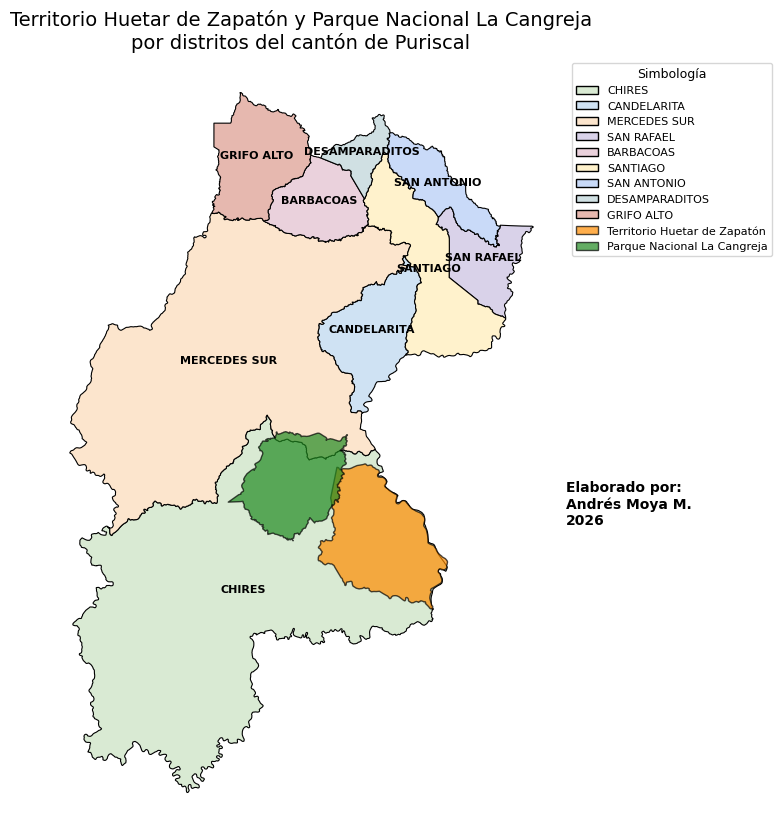

In [38]:

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Crear figura y ejes
fig, ax = plt.subplots(figsize=(12, 10))

# Paleta de colores para los distritos
colores = [
    "#D9EAD3", "#CFE2F3", "#FCE5CD",
    "#D9D2E9", "#EAD1DC", "#FFF2CC",
    "#C9DAF8", "#D0E0E3", "#E6B8AF"
]

# Dibujar cada distrito con un color diferente
for i, (idx, row) in enumerate(distritos_puriscal.iterrows()):
    distritos_puriscal.loc[[idx]].plot(
        ax=ax,
        color=colores[i % len(colores)],
        edgecolor="black",
        linewidth=0.8
    )

# Territorio Huetar de Zapatón
zapaton.plot(
    ax=ax,
    color="darkorange",
    edgecolor="black",
    alpha=0.7,
    label="Territorio Huetar de Zapatón"
)

# Parque Nacional La Cangreja
cangreja.plot(
    ax=ax,
    color="forestgreen",
    edgecolor="black",
    alpha=0.7,
    label="Parque Nacional La Cangreja"
)

# Nombres de los distritos
for idx, row in distritos_puriscal.iterrows():
    centroide = row.geometry.centroid

    ax.annotate(
        text=row["nom_distr"],
        xy=(centroide.x, centroide.y),
        ha="center",
        fontsize=8,
        color="black",
        weight="bold"
    )

# Crear elementos de la leyenda para cada distrito
elementos_leyenda = []

for i, (idx, row) in enumerate(distritos_puriscal.iterrows()):
    elementos_leyenda.append(
        mpatches.Patch(
            facecolor=colores[i % len(colores)],
            edgecolor="black",
            label=row["nom_distr"]
        )
    )

# Agregar Territorio Huetar y Parque Nacional a la leyenda
elementos_leyenda.append(
    mpatches.Patch(
        facecolor="darkorange",
        edgecolor="black",
        alpha=0.7,
        label="Territorio Huetar de Zapatón"
    )
)

elementos_leyenda.append(
    mpatches.Patch(
        facecolor="forestgreen",
        edgecolor="black",
        alpha=0.7,
        label="Parque Nacional La Cangreja"
    )
)

# Título del mapa
ax.set_title(
    "Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
    "por distritos del cantón de Puriscal",
    fontsize=14
)

# Leyenda a la derecha
ax.legend(
    handles=elementos_leyenda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8,
    title="Simbología",
    title_fontsize=9
)

# Nombre y año debajo de la leyenda
ax.text(
    1.02, 0.45,
    "Elaborado por:\nAndrés Moya M.\n2026",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="top",
    weight="bold"
)

# Reservar espacio a la derecha
fig.subplots_adjust(right=0.72)

# Eliminar ejes
ax.set_axis_off()

# Mostrar mapa
plt.show()


##Respuesta 1

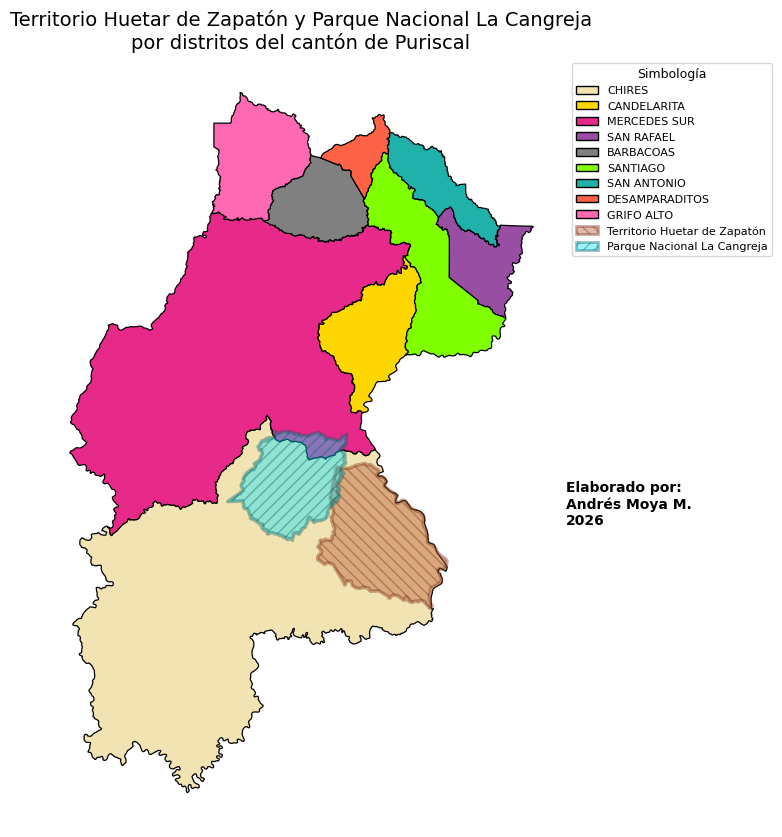

In [39]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Crear figura y ejes
fig, ax = plt.subplots(figsize=(12, 10))

# Colores contrastantes para cada distrito
colores = [
    "#F2E3B3",  # Beige arena (Chires)
    "#FFD700",  # Amarillo
    "#E7298A",  # Magenta
    "#984EA3",  # Violeta
    "#808080",  # Gris
    "#7FFF00",  # Verde lima
    "#20B2AA",  # Turquesa
    "#FF6347",  # Coral
    "#FF69B4"   # Rosa
]

# Colores del territorio y el parque
COLOR_ZAPATON = "#B5502D"    # Terracota
BORDE_ZAPATON = "#7A2E14"    # Terracota oscuro (borde y rayado)
COLOR_CANGREJA = "#00E5FF"   # Cian brillante
BORDE_CANGREJA = "#006064"   # Cian oscuro

# Dibujar cada distrito con un color diferente
for i, (idx, row) in enumerate(distritos_puriscal.iterrows()):
    distritos_puriscal.loc[[idx]].plot(
        ax=ax,
        color=colores[i % len(colores)],
        edgecolor="black",
        linewidth=0.9,
        zorder=1
    )

# Territorio Huetar de Zapatón (terracota, rayado \\\)
zapaton.plot(
    ax=ax,
    facecolor=COLOR_ZAPATON,
    edgecolor=BORDE_ZAPATON,
    linewidth=2.5,
    alpha=0.40,
    hatch="\\\\\\",
    zorder=2
)

# Parque Nacional La Cangreja (rayado ///)
cangreja.plot(
    ax=ax,
    facecolor=COLOR_CANGREJA,
    edgecolor=BORDE_CANGREJA,
    linewidth=2.5,
    alpha=0.40,
    hatch="///",
    zorder=3
)

# Crear elementos de la leyenda
elementos_leyenda = []

# Agregar distritos a la leyenda
for i, (idx, row) in enumerate(distritos_puriscal.iterrows()):
    elementos_leyenda.append(
        mpatches.Patch(
            facecolor=colores[i % len(colores)],
            edgecolor="black",
            label=row["nom_distr"]
        )
    )

# Agregar Territorio Huetar
elementos_leyenda.append(
    mpatches.Patch(
        facecolor=COLOR_ZAPATON,
        edgecolor=BORDE_ZAPATON,
        alpha=0.40,
        hatch="\\\\\\",
        linewidth=2,
        label="Territorio Huetar de Zapatón"
    )
)

# Agregar Parque Nacional
elementos_leyenda.append(
    mpatches.Patch(
        facecolor=COLOR_CANGREJA,
        edgecolor=BORDE_CANGREJA,
        alpha=0.40,
        hatch="///",
        linewidth=2,
        label="Parque Nacional La Cangreja"
    )
)

# Título del mapa
ax.set_title(
    "Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
    "por distritos del cantón de Puriscal",
    fontsize=14
)

# Leyenda a la derecha
ax.legend(
    handles=elementos_leyenda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8,
    title="Simbología",
    title_fontsize=9
)

# Nombre y año
ax.text(
    1.02, 0.45,
    "Elaborado por:\nAndrés Moya M.\n2026",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="top",
    weight="bold"
)

# Reservar espacio a la derecha
fig.subplots_adjust(right=0.72)

# Eliminar ejes
ax.set_axis_off()

# Mostrar mapa
plt.show()

ÁREA DEL TERRITORIO Y DEL PARQUE POR DISTRITO (hectáreas)

   nom_distr  area_distrito_ha  zapaton_ha  zapaton_pct  cangreja_ha  cangreja_pct  zapaton_pct_distrito  cangreja_pct_distrito
      CHIRES          22965.85     3482.28        100.0      2270.59         88.23                 15.16                   9.89
MERCEDES SUR          18355.27        0.00          0.0       302.79         11.77                  0.00                   1.65

Territorio de Zapatón: capa = 3,498.00 ha | suma por distrito = 3,482.28 ha
Parque La Cangreja:    capa = 2,573.39 ha | suma por distrito = 2,573.38 ha


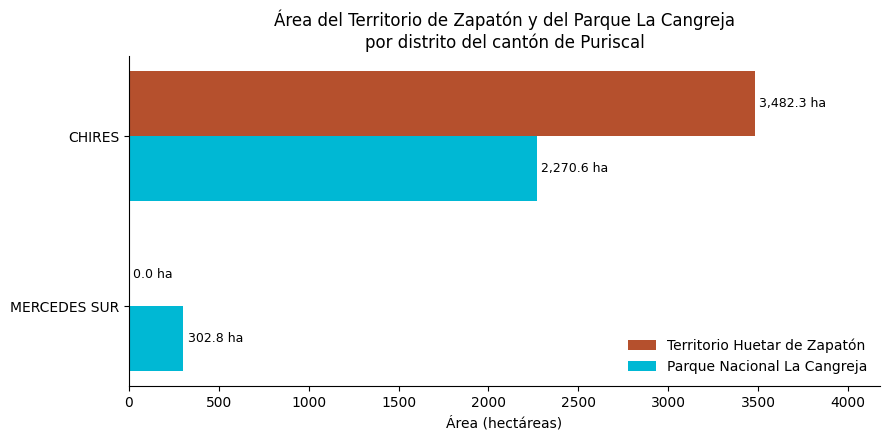

In [40]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 0. Crear distritos_puriscal si todavía no existe
# ------------------------------------------------------------
if "distritos_puriscal" not in globals():
    distritos_puriscal = distritos[
        distritos["canton"].str.strip().str.upper() == "PURISCAL"
    ].copy()

# ------------------------------------------------------------
# 1. Preparación: CRS métrico (CRTM05) y geometrías válidas
# ------------------------------------------------------------
CRS_METRICO = 5367

dist_m = distritos_puriscal.to_crs(CRS_METRICO)[["nom_distr", "geometry"]].copy()
zap_m  = zapaton.to_crs(CRS_METRICO)[["geometry"]].copy()
cang_m = cangreja.to_crs(CRS_METRICO)[["geometry"]].copy()

for capa in (dist_m, zap_m, cang_m):
    capa["geometry"] = capa.geometry.make_valid()

# Área total de cada distrito, en hectáreas
dist_m["area_distrito_ha"] = dist_m.geometry.area / 10_000

# ------------------------------------------------------------
# 2. overlay (intersection) + dissolve + área en hectáreas
# ------------------------------------------------------------
def area_por_distrito(capa, nombre):
    inter = gpd.overlay(capa, dist_m[["nom_distr", "geometry"]],
                        how="intersection", keep_geom_type=True)
    inter = inter.dissolve(by="nom_distr").reset_index()
    inter[f"{nombre}_ha"] = inter.geometry.area / 10_000
    inter[f"{nombre}_pct"] = inter[f"{nombre}_ha"] / inter[f"{nombre}_ha"].sum() * 100
    return inter[["nom_distr", f"{nombre}_ha", f"{nombre}_pct"]]

zap_dist  = area_por_distrito(zap_m,  "zapaton")
cang_dist = area_por_distrito(cang_m, "cangreja")

# ------------------------------------------------------------
# 3. Tabla combinada
# ------------------------------------------------------------
tabla = (
    dist_m[["nom_distr", "area_distrito_ha"]]
    .merge(zap_dist,  on="nom_distr", how="left")
    .merge(cang_dist, on="nom_distr", how="left")
    .fillna(0)
)

tabla["zapaton_pct_distrito"]  = tabla["zapaton_ha"]  / tabla["area_distrito_ha"] * 100
tabla["cangreja_pct_distrito"] = tabla["cangreja_ha"] / tabla["area_distrito_ha"] * 100

# Solo distritos con alguna de las dos capas
tabla = tabla[(tabla["zapaton_ha"] > 0) | (tabla["cangreja_ha"] > 0)]
tabla = tabla.sort_values("cangreja_ha", ascending=False).round(2).reset_index(drop=True)

print("ÁREA DEL TERRITORIO Y DEL PARQUE POR DISTRITO (hectáreas)\n")
print(tabla.to_string(index=False))

# ------------------------------------------------------------
# 4. Verificación: la suma por distrito vs. el área total de la capa
# ------------------------------------------------------------
total_zap  = zap_m.geometry.area.sum()  / 10_000
total_cang = cang_m.geometry.area.sum() / 10_000

print(f"\nTerritorio de Zapatón: capa = {total_zap:,.2f} ha | suma por distrito = {tabla['zapaton_ha'].sum():,.2f} ha")
print(f"Parque La Cangreja:    capa = {total_cang:,.2f} ha | suma por distrito = {tabla['cangreja_ha'].sum():,.2f} ha")

# ------------------------------------------------------------
# 5. Gráfico de barras comparativo
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))

y = range(len(tabla))
alto = 0.38

b1 = ax.barh([i - alto / 2 for i in y], tabla["zapaton_ha"], height=alto,
             color="#B5502D", label="Territorio Huetar de Zapatón")
b2 = ax.barh([i + alto / 2 for i in y], tabla["cangreja_ha"], height=alto,
             color="#00B8D4", label="Parque Nacional La Cangreja")

ax.bar_label(b1, labels=[f"{v:,.1f} ha" for v in tabla["zapaton_ha"]], padding=3, fontsize=9)
ax.bar_label(b2, labels=[f"{v:,.1f} ha" for v in tabla["cangreja_ha"]], padding=3, fontsize=9)

ax.set_yticks(list(y))
ax.set_yticklabels(tabla["nom_distr"])
ax.invert_yaxis()
ax.set_xlabel("Área (hectáreas)")
ax.set_title("Área del Territorio de Zapatón y del Parque La Cangreja\npor distrito del cantón de Puriscal")
ax.set_xlim(0, max(tabla["zapaton_ha"].max(), tabla["cangreja_ha"].max()) * 1.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

### Este gráfico indica qué porcentaje del total del territorio cada capa (Territorio y Parque Nacional) caen en cada distrito puriscaleño.

## Respuesta 2

In [64]:
import geopandas as gpd
import folium

# 1. Cargar tu capa local de ríos subida a Colab
rios = gpd.read_file("Prueba_rio.shp")

# Asegurar coordenadas geográficas estándar (EPSG:4326)
if rios.crs != "EPSG:4326":
    rios = rios.to_crs(epsg=4326)

# 2. Proyectar a sistema métrico (CRTM05 / EPSG:5367) para calcular distancias precisas
zapaton_m = zapaton.to_crs(epsg=5367)
cangreja_m = cangreja.to_crs(epsg=5367)

# Crear área de estudio y buffer de proximidad de 2 km (2000 metros)
area_estudio_geom = gpd.GeoSeries(
    [zapaton_m.union_all(), cangreja_m.union_all()], crs="EPSG:5367"
).union_all()
buffer_zona = gpd.GeoSeries([area_estudio_geom], crs="EPSG:5367").buffer(2000)

rios_m = rios.to_crs(epsg=5367)
rios_cercanos = rios_m[rios_m.intersects(buffer_zona.iloc[0])].copy()

# 3. Detectar automáticamente la columna que contiene el nombre del río o quebrada
candidatos = [
    c
    for c in rios_cercanos.columns
    if any(
        x in c.lower()
        for x in ["nombre", "nom_rio", "desc", "label", "fna", "toponimo"]
    )
]
if candidatos:
    col_nombre = candidatos[0]
else:
    col_nombre = (
        rios_cercanos.columns[1]
        if len(rios_cercanos.columns) > 1
        else rios_cercanos.columns[0]
    )

rios_cercanos[col_nombre] = rios_cercanos[col_nombre].fillna(
    "Sin nombre oficial"
)


# Clasificar la relación espacial respecto a Zapatón y La Cangreja
def clasificar(geom):
    en_zapaton = geom.intersects(zapaton_m.union_all())
    en_cangreja = geom.intersects(cangreja_m.union_all())
    if en_zapaton and en_cangreja:
        return "Atraviesa Zapatón y La Cangreja"
    elif en_zapaton:
        return "Atraviesa T.I. Huetar de Zapatón"
    elif en_cangreja:
        return "Atraviesa P.N. La Cangreja"
    else:
        return "Próximo (radio de 2 km)"


rios_cercanos["Relacion"] = rios_cercanos.geometry.apply(clasificar)
rios_final = rios_cercanos.to_crs(epsg=4326)

# 4. Generar el Mapa Interactivo con Tooltips
mapa = distritos_puriscal.explore(
    name="Distritos de Puriscal",
    color="lightgray",
    style_kwds={"fillOpacity": 0.1, "weight": 1},
    tooltip=["nom_distr"],
    tiles="CartoDB positron",
)

zapaton.explore(
    m=mapa,
    name="T.I. Huetar de Zapatón",
    color="darkorange",
    style_kwds={"fillOpacity": 0.4, "weight": 2},
    tooltip=["Nombre"],
)

cangreja.explore(
    m=mapa,
    name="P.N. La Cangreja",
    color="forestgreen",
    style_kwds={"fillOpacity": 0.4, "weight": 2},
    tooltip=["nombre_asp"],
)

rios_final.explore(
    m=mapa,
    name="Ríos y Quebradas (2 km)",
    color="blue",
    style_kwds={"weight": 2.5, "opacity": 0.8},
    highlight_kwds={"weight": 5, "color": "cyan"},
    tooltip=[col_nombre, "Relacion"],
)

folium.LayerControl(collapsed=False).add_to(mapa)
mapa

/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


In [65]:
import pandas as pd

# 1. Agrupar y procesar la información de los ríos cercanos / que cruzan (radio de 2 km)
tabla_conteo = (
    rios_final.groupby([col_nombre, "Relacion"])
    .size()
    .reset_index(name="Cantidad_Segmentos")
)

# 2. Ordenar de mayor a menor cantidad de tramos y renombrar columnas formalmente
tabla_presentacion = tabla_conteo.rename(
    columns={
        col_nombre: "Nombre del Río o Quebrada",
        "Relacion": "Relación Espacial con Zapatón y La Cangreja",
        "Cantidad_Segmentos": "Número de Tramos Registrados",
    }
).sort_values(by="Número de Tramos Registrados", ascending=False)

# Mostrar la tabla formateada en la celda
print("=== TABLA A: CONTEO Y CLASIFICACIÓN DE LA RED HÍDRICA (RADIO 2 KM) ===")
display(tabla_presentacion.reset_index(drop=True))

=== TABLA A: CONTEO Y CLASIFICACIÓN DE LA RED HÍDRICA (RADIO 2 KM) ===


,Nombre del Río o Quebrada,Relación Espacial con Zapatón y La Cangreja,Número de Tramos Registrados
0,Río Candelaria,Atraviesa T.I. Huetar de Zapatón,4
1,Río Candelaria,Próximo (radio de 2 km),2
2,Río Cajón,Próximo (radio de 2 km),2
3,Río Rey,Atraviesa T.I. Huetar de Zapatón,2
4,Quebrada Bijagual,Próximo (radio de 2 km),2
5,Quebrada Carate,Próximo (radio de 2 km),1
6,Quebrada Bejuco,Atraviesa T.I. Huetar de Zapatón,1
7,Quebrada Azul,Atraviesa P.N. La Cangreja,1
8,Quebrada Achiote,Próximo (radio de 2 km),1
9,Quebrada Colorado,Próximo (radio de 2 km),1


### La tabla superior presenta el resumen y conteo de los tramos hídricos identificados en un radio de proximidad de 2 kilómetros respecto al Territorio Indígena Huetar de Zapatón y al Parque Nacional La Cangreja, en el cantón de Puriscal. A través de la intersección geométrica y el análisis de áreas de influencia (buffer), se categorizan los cauces que atraviesan directamente ambas zonas de interés o discurren en sus inmediaciones, permitiendo cuantificar el número de segmentos cartográficos asociados a cada denominación oficial. Estos datos reflejan la densidad y conectividad de la red de drenaje local, un factor crítico para la gestión ambiental, la protección de recursos hídricos y la conservación de los ecosistemas fluviales en la región. De igul forma la representacion de estos cuerpos de agua es fundamental ya que muchos de los lugares de importancia cultural para la poblacion indigena Huetar de Zapatón nace de dichos cuerpos de agua

## Respuesta 3

Traslape calculado:       70.97 ha
Traslape según SINAC:     68.05 ha
Diferencia:               +2.92 ha (+4.3 %)


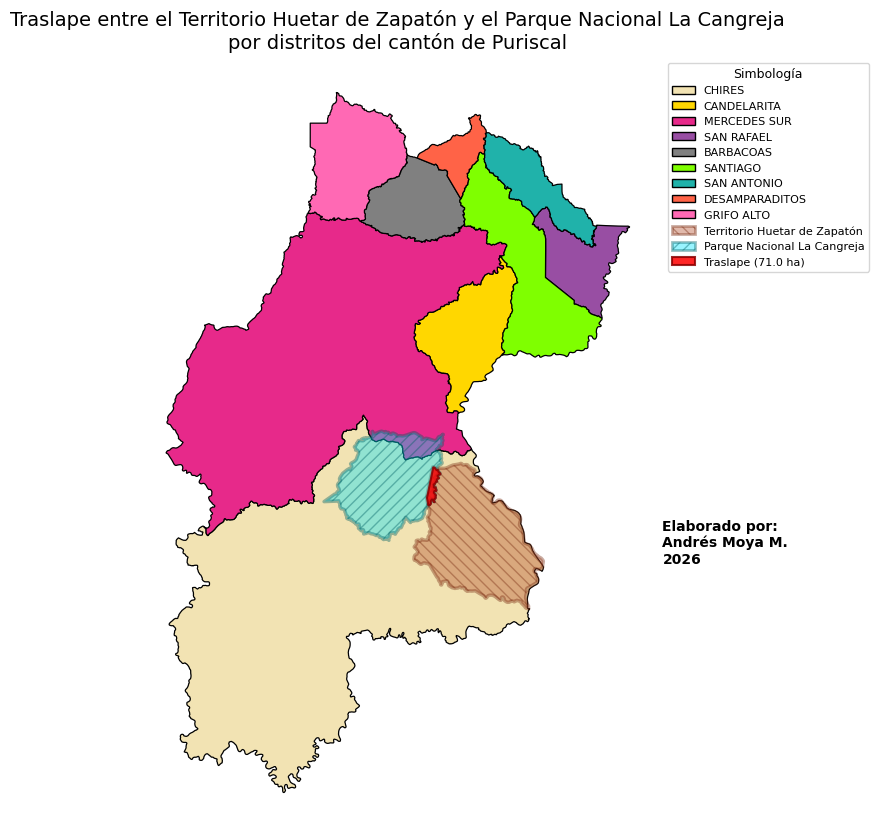

In [66]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ------------------------------------------------------------
# 1. OPERACIÓN ESPACIAL: intersección Territorio ∩ Parque
# ------------------------------------------------------------

# CRS proyectado en metros (CRTM05) para medir áreas correctamente
CRS_METRICO = 5367
zap_m = zapaton.to_crs(CRS_METRICO)
cang_m = cangreja.to_crs(CRS_METRICO)

# Reparar geometrías inválidas, que suelen dar errores en overlay
zap_m["geometry"] = zap_m.geometry.make_valid()
cang_m["geometry"] = cang_m.geometry.make_valid()

# Intersección (solo la geometría, para evitar conflictos de columnas)
traslape_m = gpd.overlay(
    zap_m[["geometry"]],
    cang_m[["geometry"]],
    how="intersection"
)

# Conservar solo polígonos (a veces la intersección genera líneas o puntos)
traslape_m = traslape_m[traslape_m.geom_type.isin(["Polygon", "MultiPolygon"])]

# ------------------------------------------------------------
# 2. VERIFICACIÓN CONTRA EL PLAN DE MANEJO
# ------------------------------------------------------------
area_ha = traslape_m.geometry.area.sum() / 10_000
area_oficial = 68.05
diferencia = area_ha - area_oficial

print(f"Traslape calculado:       {area_ha:,.2f} ha")
print(f"Traslape según SINAC:     {area_oficial:,.2f} ha")
print(f"Diferencia:               {diferencia:+,.2f} ha ({diferencia / area_oficial * 100:+.1f} %)")

# Volver al CRS original de tus capas para dibujar junto con los distritos
traslape = traslape_m.to_crs(distritos_puriscal.crs)

# ------------------------------------------------------------
# 3. MAPA CON EL TRASLAPE EN ROJO
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 10))

colores = [
    "#F2E3B3",  # Beige arena (Chires)
    "#FFD700",  # Amarillo
    "#E7298A",  # Magenta
    "#984EA3",  # Violeta
    "#808080",  # Gris
    "#7FFF00",  # Verde lima
    "#20B2AA",  # Turquesa
    "#FF6347",  # Coral
    "#FF69B4"   # Rosa
]

COLOR_ZAPATON = "#B5502D"
BORDE_ZAPATON = "#7A2E14"
COLOR_CANGREJA = "#00E5FF"
BORDE_CANGREJA = "#006064"
COLOR_TRASLAPE = "#FF0000"
BORDE_TRASLAPE = "#8B0000"

# Distritos
for i, (idx, row) in enumerate(distritos_puriscal.iterrows()):
    distritos_puriscal.loc[[idx]].plot(
        ax=ax,
        color=colores[i % len(colores)],
        edgecolor="black",
        linewidth=0.9,
        zorder=1
    )

# Territorio Huetar de Zapatón (rayado \\\)
zapaton.plot(
    ax=ax,
    facecolor=COLOR_ZAPATON,
    edgecolor=BORDE_ZAPATON,
    linewidth=2.5,
    alpha=0.40,
    hatch="\\\\\\",
    zorder=2
)

# Parque Nacional La Cangreja (rayado ///)
cangreja.plot(
    ax=ax,
    facecolor=COLOR_CANGREJA,
    edgecolor=BORDE_CANGREJA,
    linewidth=2.5,
    alpha=0.40,
    hatch="///",
    zorder=3
)

# Traslape (rojo, resultado de la intersección)
traslape.plot(
    ax=ax,
    facecolor=COLOR_TRASLAPE,
    edgecolor=BORDE_TRASLAPE,
    linewidth=1.5,
    alpha=0.85,
    zorder=4
)

# Leyenda
elementos_leyenda = []

for i, (idx, row) in enumerate(distritos_puriscal.iterrows()):
    elementos_leyenda.append(
        mpatches.Patch(
            facecolor=colores[i % len(colores)],
            edgecolor="black",
            label=row["nom_distr"]
        )
    )

elementos_leyenda.append(
    mpatches.Patch(
        facecolor=COLOR_ZAPATON, edgecolor=BORDE_ZAPATON,
        alpha=0.40, hatch="\\\\\\", linewidth=2,
        label="Territorio Huetar de Zapatón"
    )
)
elementos_leyenda.append(
    mpatches.Patch(
        facecolor=COLOR_CANGREJA, edgecolor=BORDE_CANGREJA,
        alpha=0.40, hatch="///", linewidth=2,
        label="Parque Nacional La Cangreja"
    )
)
elementos_leyenda.append(
    mpatches.Patch(
        facecolor=COLOR_TRASLAPE, edgecolor=BORDE_TRASLAPE,
        alpha=0.85, linewidth=1.5,
        label=f"Traslape ({area_ha:,.1f} ha)"
    )
)

ax.set_title(
    "Traslape entre el Territorio Huetar de Zapatón y el Parque Nacional La Cangreja\n"
    "por distritos del cantón de Puriscal",
    fontsize=14
)

ax.legend(
    handles=elementos_leyenda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8,
    title="Simbología",
    title_fontsize=9
)

ax.text(
    1.02, 0.40,
    "Elaborado por:\nAndrés Moya M.\n2026",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="top",
    weight="bold"
)

fig.subplots_adjust(right=0.72)
ax.set_axis_off()
plt.show()

Distritos representados: ['CHIRES', 'MERCEDES SUR']

SUPERFICIES POR DISTRITO
    Distrito  Territorio Zapatón (ha)  Parque La Cangreja (ha)  Traslape (ha)
      CHIRES                  3482.28                  2270.59          70.97
MERCEDES SUR                     0.00                   302.79           0.00


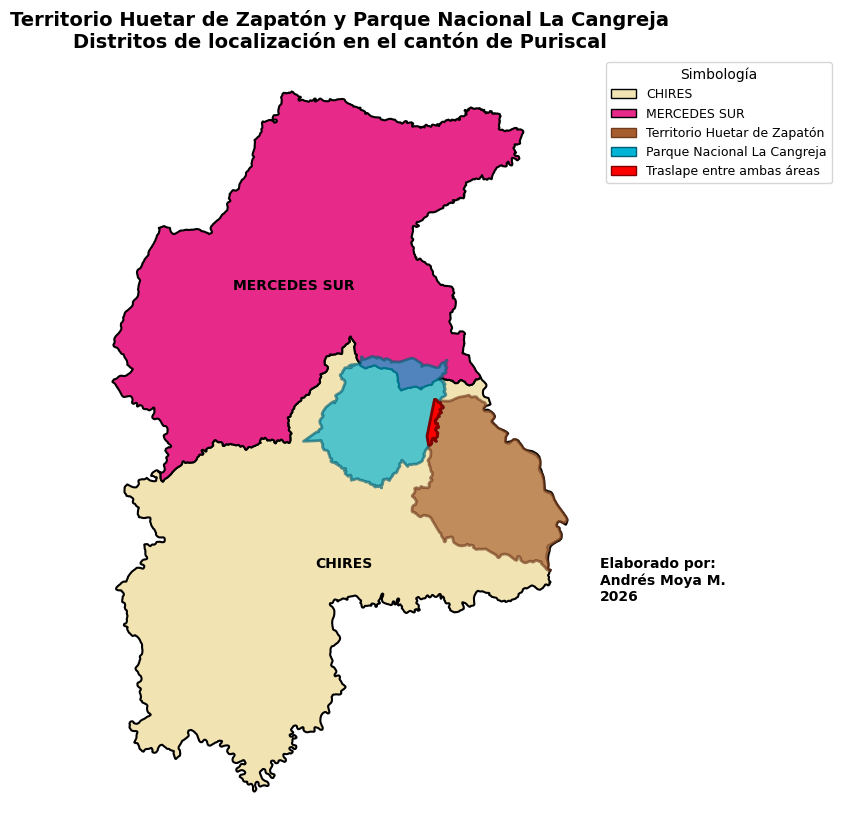

In [68]:

import requests
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

CRS_METRICO = 5367

# ============================================================
# 1. CARGA DE DATOS
# ============================================================

url_distritos = (
    "https://services5.arcgis.com/4u1m1BBDkNDTVWsd/"
    "arcgis/rest/services/Distritos_CR/FeatureServer/0/query"
    "?where=1%3D1&outFields=*&returnGeometry=true&outSR=4326&f=geojson"
)

distritos = gpd.read_file(url_distritos)

puriscal = distritos[
    distritos["canton"].str.strip().str.upper() == "PURISCAL"
].copy()

url_territorios = (
    "https://services1.arcgis.com/aWQmxJWy7lM2Qqmo/"
    "arcgis/rest/services/CE_Publicos_CR/FeatureServer/4/query"
    "?where=1%3D1&outFields=*&returnGeometry=true&outSR=4326&f=geojson"
)

territorios = gpd.read_file(url_territorios)

zapaton = territorios[
    territorios["Nombre"].str.strip().str.upper() == "ZAPATÓN"
].copy()

url_asp = (
    "https://services9.arcgis.com/RrvMEynxDB8hycVO/"
    "ArcGIS/rest/services/ÁSP_Costa_Rica_2021/FeatureServer/0/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

respuesta = requests.get(url_asp, params=params)
respuesta.raise_for_status()

areas_protegidas = gpd.GeoDataFrame.from_features(
    respuesta.json()["features"], crs="EPSG:4326"
)

cangreja = areas_protegidas[
    areas_protegidas["nombre_asp"].str.contains(
        "La Cangreja", case=False, na=False
    )
].copy()

# ============================================================
# 2. REPARAR GEOMETRÍAS
# ============================================================

def reparar(gdf):
    gdf = gdf.to_crs(4326).copy()
    try:
        gdf["geometry"] = gdf.geometry.make_valid()
    except AttributeError:
        gdf["geometry"] = gdf.geometry.buffer(0)
    return gdf

puriscal = reparar(puriscal)
zapaton = reparar(zapaton)
cangreja = reparar(cangreja)

# ============================================================
# 3. IDENTIFICAR SOLO LOS DISTRITOS NECESARIOS
# ============================================================

d_zapaton = gpd.sjoin(
    puriscal,
    zapaton[["geometry"]],
    how="inner",
    predicate="intersects"
)

d_cangreja = gpd.sjoin(
    puriscal,
    cangreja[["geometry"]],
    how="inner",
    predicate="intersects"
)

nombres = sorted(
    set(d_zapaton["nom_distr"].unique()) |
    set(d_cangreja["nom_distr"].unique())
)

# SOLO estos distritos aparecerán en el mapa
distritos_sel = puriscal[
    puriscal["nom_distr"].isin(nombres)
].copy()

print("Distritos representados:", nombres)

# ============================================================
# 4. RECORTAR LAS ÁREAS A LOS DISTRITOS SELECCIONADOS
# ============================================================

zapaton_rec = gpd.clip(zapaton, distritos_sel)
cangreja_rec = gpd.clip(cangreja, distritos_sel)

# ============================================================
# 5. CALCULAR EL TRASLAPE REAL
# ============================================================

zapaton_m = zapaton_rec.to_crs(CRS_METRICO)
cangreja_m = cangreja_rec.to_crs(CRS_METRICO)

geom_zap = zapaton_m.geometry.union_all()
geom_can = cangreja_m.geometry.union_all()

geom_traslape = geom_zap.intersection(geom_can)

traslape = gpd.GeoDataFrame(
    {"Nombre": ["Traslape"]},
    geometry=[geom_traslape],
    crs=f"EPSG:{CRS_METRICO}"
).to_crs(4326)

# ============================================================
# 6. TABLA DE HECTÁREAS POR DISTRITO
# ============================================================

def hectareas(capa, distrito_geom):
    mascara = gpd.GeoDataFrame(
        geometry=[distrito_geom], crs=4326
    )
    parte = gpd.clip(capa, mascara)
    return parte.to_crs(CRS_METRICO).geometry.area.sum() / 10000

filas = []

for _, d in distritos_sel.iterrows():
    filas.append({
        "Distrito": d["nom_distr"],
        "Territorio Zapatón (ha)": round(
            hectareas(zapaton_rec, d.geometry), 2
        ),
        "Parque La Cangreja (ha)": round(
            hectareas(cangreja_rec, d.geometry), 2
        ),
        "Traslape (ha)": round(
            hectareas(traslape, d.geometry), 2
        )
    })

print("\nSUPERFICIES POR DISTRITO")
print(pd.DataFrame(filas).to_string(index=False))

# ============================================================
# 7. MAPA: EXCLUSIVAMENTE LOS DISTRITOS SELECCIONADOS
# ============================================================

COLOR_ZAP = "#A65E2E"
BORDE_ZAP = "#713B1D"

COLOR_CAN = "#00B4D8"
BORDE_CAN = "#005F73"

COLOR_TRASLAPE = "#FF0000"

# Colores para los distritos seleccionados
COLORES_DISTRITO = {
    "CHires": "#F2E3B3",
    "CHIRES": "#F2E3B3",
    "MERCEDES SUR": "#E7298A"
}

fig, ax = plt.subplots(figsize=(12, 10))

# A. ÚNICAMENTE los distritos donde se ubican las áreas
for _, d in distritos_sel.iterrows():

    nombre = d["nom_distr"]

    gpd.GeoDataFrame(
        [d], crs=4326
    ).plot(
        ax=ax,
        facecolor=COLORES_DISTRITO.get(nombre, "#DDDDDD"),
        edgecolor="black",
        linewidth=1.5,
        zorder=1
    )

# B. Territorio Huetar de Zapatón
zapaton_rec.plot(
    ax=ax,
    facecolor=COLOR_ZAP,
    edgecolor=BORDE_ZAP,
    linewidth=2,
    alpha=0.65,
    zorder=2
)

# C. Parque Nacional La Cangreja
cangreja_rec.plot(
    ax=ax,
    facecolor=COLOR_CAN,
    edgecolor=BORDE_CAN,
    linewidth=2,
    alpha=0.65,
    zorder=3
)

# D. Traslape en rojo (por encima de ambas capas)
if not geom_traslape.is_empty:
    traslape.plot(
        ax=ax,
        facecolor=COLOR_TRASLAPE,
        edgecolor="#800000",
        linewidth=2,
        alpha=1,
        zorder=4
    )

# E. Nombres de los distritos
for _, d in distritos_sel.iterrows():

    p = d.geometry.representative_point()

    ax.annotate(
        d["nom_distr"],
        xy=(p.x, p.y),
        ha="center",
        va="center",
        fontsize=10,
        weight="bold",
        zorder=5
    )

# ============================================================
# 8. LEYENDA
# ============================================================

leyenda = []

for nombre in nombres:
    leyenda.append(
        mpatches.Patch(
            facecolor=COLORES_DISTRITO.get(nombre, "#DDDDDD"),
            edgecolor="black",
            label=nombre
        )
    )

leyenda += [
    mpatches.Patch(
        facecolor=COLOR_ZAP,
        edgecolor=BORDE_ZAP,
        label="Territorio Huetar de Zapatón"
    ),
    mpatches.Patch(
        facecolor=COLOR_CAN,
        edgecolor=BORDE_CAN,
        label="Parque Nacional La Cangreja"
    ),
    mpatches.Patch(
        facecolor=COLOR_TRASLAPE,
        edgecolor="#800000",
        label="Traslape entre ambas áreas"
    )
]

ax.set_title(
    "Territorio Huetar de Zapatón y Parque Nacional La Cangreja\n"
    "Distritos de localización en el cantón de Puriscal",
    fontsize=14,
    weight="bold"
)

ax.legend(
    handles=leyenda,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9,
    title="Simbología"
)

ax.text(
    1.02, 0.35,
    "Elaborado por:\nAndrés Moya M.\n2026",
    transform=ax.transAxes,
    fontsize=10,
    ha="left",
    va="top",
    weight="bold"
)

fig.subplots_adjust(right=0.72)
ax.set_axis_off()

plt.show()


## Conclusiones
### Respuesta 1
### El Territorio Huetar de Zapatón queda totalmente en Chires. Ocupa unas 3.482 ha, el 15,2 % del distrito.
### El Parque Nacional La Cangreja se reparte entre Chires (2.271 ha, 88 % del Parque) y Mercedes Sur (303 ha, 12 %).
### Respuesta 2
### Con un buffer de 2 km alrededor de ambas áreas se identificaron decenas de tramos de cauces.
### Se clasificaron en cuatro categorías: atraviesan solo Zapatón (Candelaria, Rey, Bejuco, Jucó, Lajas), atraviesan solo el parque (Azul, Estrella, Grande), atraviesan ambos (Guatuso, Fresca) o son próximos.
### Respuesta 4
###La intersección da 70,97 ha, todas en Chires.
### Representa cerca del 2 % de Zapatón y del 2,8 % del parque.
### Es un traslape pequeño pero real, y es el punto donde el Plan de Manejo necesitaría una gobernanza compartida.

## Bibliografia
### 1. Instituto Geográfico Nacional. (s. f.). Sistema Nacional de Información Territorial (SNIT). https://www.snitcr.go.cr/.
### 2. Sistema Nacional de Áreas de Conservación. (2018). Actualización del Plan General de Manejo del Parque Nacional La Cangreja. Área de Conservación Cordillera Central.
### 3. Instituto Geográfico Nacional. (2020). Catálogo de objetos geográficos para datos fundamentales de Costa Rica: Límites territoriales administrativos.

## Declaración IA
### Se utilizo la IA para colaborarme con la busqueda de información ya que la misma se me dificulto, en mejoramiento de codigos y en apoyo para la redacción.
